# KMA/MSM – Přednáška 8: Vztahy diskrétních proměnných – kontingenční tabulky

**Blanka Šedivá, KMA FAV ZČU Plzeň**

Notebook doprovází přednášku P08 (`P08_kontingencni_tabulky.tex`).

## Obsah

1. Kontingenční tabulka, $\chi^2$ a $G^2$ test nezávislosti, Yatesova korekce – výpočet ručně a v `scipy`
2. Rozdělení $X^2$ za $H_0$ – simulace
3. Míry asociace, adjustovaná standardizovaná rezidua, mozaikový graf
4. Čtyřpolní tabulky: poměr šancí a jeho interval spolehlivosti, Fisherův exaktní test, skutečná hladina testů
5. Párová data: McNemarův, Bowkerův a Stuartův–Maxwellův test
6. Trojrozměrná tabulka UCBAdmissions: Simpsonův paradox, Cochranův–Mantelův–Haenszelův test, Breslowův–Dayův test
7. Log-lineární modely M1–M4: uzavřené odhady, IPF, Newton–Raphson, Poissonův GLM, výběr modelu

**Značení:** tabulka $r\times c$ ($r$ řádků, $c$ sloupců), četnosti $n_{ij}$, marginály $n_{i\bullet}$, $n_{\bullet j}$,
očekávané četnosti $\hat m_{ij}$. U trojrozměrných tabulek znaky $A,B,C$ s $I,J,K$ kategoriemi
(zde je $k$ index kategorie znaku $C$, nikoli dimenze).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb
from scipy import stats
from scipy.stats import chi2, chi2_contingency, fisher_exact, binomtest, norm
from scipy.stats.contingency import association, expected_freq
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import (Table, Table2x2, SquareTable,
                                                  StratifiedTable, mcnemar)
from statsmodels.graphics.mosaicplot import mosaic

RNG = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
np.set_printoptions(precision=4, suppress=True)

---
# 1. $\chi^2$ a $G^2$ test nezávislosti

Příklad z přednášky: tabulka $2\times 2$ s četnostmi $\begin{pmatrix}30&10\\20&40\end{pmatrix}$.
Nejprve vše spočteme ručně podle vzorců
$$\hat m_{ij}=\frac{n_{i\bullet}n_{\bullet j}}{n},\qquad X^2=\sum_{i,j}\frac{(n_{ij}-\hat m_{ij})^2}{\hat m_{ij}},\qquad
G^2=2\sum_{i,j}n_{ij}\ln\frac{n_{ij}}{\hat m_{ij}},\qquad \text{df}=(r-1)(c-1).$$

In [2]:
table = np.array([[30, 10], [20, 40]])
n = table.sum()
row, col = table.sum(axis=1), table.sum(axis=0)
m = np.outer(row, col) / n                     # očekávané četnosti
X2 = ((table - m) ** 2 / m).sum()
G2 = 2 * np.sum(table * np.log(table / m))
r, c = table.shape
dof = (r - 1) * (c - 1)
print("očekávané četnosti:\n", m)
print(f"X2 = {X2:.4f}, p = {chi2.sf(X2, dof):.3g}")
print(f"G2 = {G2:.4f}, p = {chi2.sf(G2, dof):.3g}")

očekávané četnosti:
 [[20. 20.]
 [30. 30.]]
X2 = 16.6667, p = 4.46e-05
G2 = 17.2609, p = 3.26e-05


Totéž pomocí `scipy.stats.chi2_contingency`. **Pozor:** výchozí volání u tabulky s 1 stupněm volnosti
provádí Yatesovu korekci (`correction=True`).

In [3]:
res = chi2_contingency(table, correction=False)
print("Pearson bez korekce:", res.statistic, res.pvalue, res.dof)
res_y = chi2_contingency(table)                 # výchozí -> Yates
print("výchozí (Yates):    ", res_y.statistic, res_y.pvalue)
res_g = chi2_contingency(table, correction=False, lambda_="log-likelihood")
print("G2:                 ", res_g.statistic, res_g.pvalue)

# Yatesova korekce ručně (zkrácený vzorec pro 2x2)
n11, n12, n21, n22 = table.ravel()
X2_Y = n * (abs(n11 * n22 - n12 * n21) - n / 2) ** 2 / (row.prod() * col.prod())
print("Yates ručně:        ", X2_Y)

Pearson bez korekce: 16.666666666666668 4.455709060405612e-05 1
výchozí (Yates):     15.041666666666666 0.00010516355403363098
G2:                  17.260924347106844 3.258188094698204e-05
Yates ručně:         15.041666666666666


Ruční výpočet souhlasí se `scipy`: $X^2=16{,}67$ ($p=4{,}5\cdot10^{-5}$), s Yatesovou korekcí $15{,}04$ ($p=1{,}05\cdot10^{-4}$),
$G^2=17{,}26$. Všechny varianty vedou k zamítnutí nezávislosti; korekce p-hodnotu zvětšuje (je konzervativní).

### Test nezávislosti v tabulce $r\times c$ – data o přijímacím řízení
Použijeme data UCBAdmissions (Berkeley 1973), která podrobně rozebereme v sekci 6. Zde tabulka obor (A–F) $\times$ výsledek.

In [4]:
depts = list("ABCDEF")
am = [512, 353, 120, 138, 53, 22]; rm = [313, 207, 205, 279, 138, 351]   # muži: přijat, odmítnut
af = [89, 17, 202, 131, 94, 24];   rf = [19, 8, 391, 244, 299, 317]       # ženy: přijata, odmítnuta
tabs = np.array([[[am[k], rm[k]], [af[k], rf[k]]] for k in range(6)])     # obor x pohlaví x výsledek

dept_adm = tabs.sum(axis=1)            # obor x (přijat, odmítnut)
gender_dept = tabs.sum(axis=2).T       # pohlaví x obor
print(pd.DataFrame(dept_adm, index=depts, columns=["přijat", "odmítnut"]))
for name, t in [("obor x výsledek", dept_adm), ("pohlaví x obor", gender_dept)]:
    rs = chi2_contingency(t, correction=False)
    print(f"{name}: X2 = {rs.statistic:.1f}, df = {rs.dof}, p = {rs.pvalue:.2g}, "
          f"min. očekávaná četnost = {rs.expected_freq.min():.1f}")

   přijat  odmítnut
A     601       332
B     370       215
C     322       596
D     269       523
E     147       437
F      46       668
obor x výsledek: X2 = 778.9, df = 5, p = 4.2e-166, min. očekávaná četnost = 226.5
pohlaví x obor: X2 = 1068.4, df = 5, p = 9.4e-229, min. očekávaná četnost = 236.8


Obě závislosti jsou extrémně silné ($X^2=778{,}9$ při 5 df, resp. $X^2=1068{,}4$ při 5 df). Podmínka na očekávané četnosti
je bohatě splněna. Obor tedy souvisí jak s úspěšností přijetí, tak s pohlavím uchazečů – to je klíč k Simpsonovu paradoxu v sekci 6.

---
# 2. Rozdělení statistiky $X^2$ za $H_0$ – simulace

Za $H_0$ (nezávislost) generujeme multinomické tabulky s $p_{ij}=p_{i\bullet}p_{\bullet j}$ a porovnáme rozdělení
$X^2$ a $G^2$ s $\chi^2((r-1)(c-1))$. Pro velké $n$ by aproximace měla být dobrá, pro malé $n$ horší.

n = 20: skutečná hladina X2 = 0.0449, G2 = 0.0753


n = 200: skutečná hladina X2 = 0.0498, G2 = 0.0520


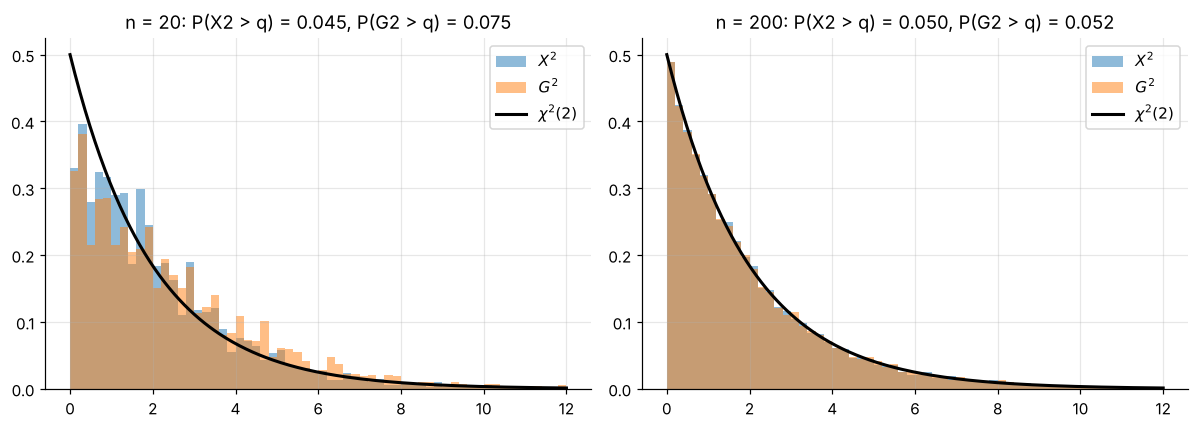

In [5]:
def sim_stats(n, p_row, p_col, B=20000, rng=RNG):
    P = np.outer(p_row, p_col).ravel()
    X2s, G2s = [], []
    tabs_sim = rng.multinomial(n, P, size=B).reshape(B, len(p_row), len(p_col))
    for t in tabs_sim:
        if (t.sum(0) == 0).any() or (t.sum(1) == 0).any():
            continue                       # degenerované tabulky vynecháme
        m = expected_freq(t)
        X2s.append(((t - m) ** 2 / m).sum())
        with np.errstate(divide="ignore", invalid="ignore"):
            G2s.append(2 * np.nansum(np.where(t > 0, t * np.log(t / m), 0)))
    return np.array(X2s), np.array(G2s)

p_row, p_col = [0.3, 0.7], [0.2, 0.3, 0.5]          # tabulka 2x3, df = 2
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, n_sim in zip(axs, [20, 200]):
    X2s, G2s = sim_stats(n_sim, p_row, p_col)
    x = np.linspace(0, 12, 300)
    ax.hist(X2s, bins=60, range=(0, 12), density=True, alpha=0.5, label="$X^2$")
    ax.hist(G2s, bins=60, range=(0, 12), density=True, alpha=0.5, label="$G^2$")
    ax.plot(x, chi2.pdf(x, 2), "k", lw=2, label=r"$\chi^2(2)$")
    q = chi2.ppf(0.95, 2)
    ax.set_title(f"n = {n_sim}: P(X2 > q) = {(X2s > q).mean():.3f}, P(G2 > q) = {(G2s > q).mean():.3f}")
    print(f"n = {n_sim}: skutečná hladina X2 = {(X2s > q).mean():.4f}, G2 = {(G2s > q).mean():.4f}")
    ax.legend()
plt.tight_layout(); plt.show()

V titulcích je skutečná hladina testů při nominální hladině 5 %. Při $n=200$ jsou obě statistiky velmi blízko $\chi^2(2)$
a skutečná hladina je kolem 0,05. Při $n=20$ (nejmenší očekávané četnosti $20\cdot0{,}3\cdot0{,}2=1{,}2$) je rozdělení zřetelně diskrétní;
$X^2$ drží hladinu stále rozumně, zatímco $G^2$ zamítá častěji (je liberální) – to odpovídá poznámce v přednášce,
že $X^2$ se obvykle lépe drží $\chi^2$ aproximace.

---
# 3. Míry asociace, rezidua a mozaikový graf

$$\varphi=\frac{n_{11}n_{22}-n_{12}n_{21}}{\sqrt{n_{1\bullet}n_{2\bullet}n_{\bullet1}n_{\bullet2}}},\qquad
V=\sqrt{\frac{X^2}{n(\min(r,c)-1)}},\qquad C=\sqrt{\frac{X^2}{X^2+n}}.$$

In [6]:
phi = (n11 * n22 - n12 * n21) / np.sqrt(row.prod() * col.prod())
V = np.sqrt(X2 / (n * (min(table.shape) - 1)))
Cc = np.sqrt(X2 / (X2 + n))
print(f"phi = {phi:.4f}, phi^2 = {phi**2:.4f} = X2/n = {X2/n:.4f}")
print(f"Cramér V = {V:.4f}  (scipy: {association(table, method='cramer'):.4f})")
print(f"kontingenční koef. C = {Cc:.4f}  (scipy: {association(table, method='pearson'):.4f})")
print(f"Tschuprowovo T = {association(table, method='tschuprow'):.4f}")

for name, t in [("obor x výsledek", dept_adm), ("pohlaví x obor", gender_dept)]:
    q = min(t.shape)
    print(f"{name}: V = {association(t, method='cramer'):.3f}, C = {association(t, method='pearson'):.3f}, "
          f"max C = {np.sqrt((q - 1) / q):.3f}")

phi = 0.4082, phi^2 = 0.1667 = X2/n = 0.1667
Cramér V = 0.4082  (scipy: 0.4082)
kontingenční koef. C = 0.3780  (scipy: 0.3780)
Tschuprowovo T = 0.4082
obor x výsledek: V = 0.415, C = 0.383, max C = 0.707
pohlaví x obor: V = 0.486, C = 0.437, max C = 0.707


Pro tabulku $2\times2$ je $V=|\varphi|=0{,}408$ (střední až silná asociace podle Cohenovy orientační škály), $C=0{,}378$.
Pro UCB data je asociace obor–výsledek $V=0{,}41$ a pohlaví–obor $V=0{,}49$. Kontingenční koeficient má u tabulek
s $\min(r,c)=2$ maximum jen $\sqrt{1/2}\approx0{,}71$, proto se hůře interpretuje než $V$.

### Ilustrace: p-hodnota vs. síla asociace
Stejná síla závislosti ($V$ konstantní) dává při rostoucím $n$ stále menší p-hodnotu.

In [7]:
base = np.array([[0.27, 0.23], [0.23, 0.27]])     # slabá asociace
for n_ in [100, 400, 1600, 6400]:
    t = np.round(base * n_).astype(int)
    rs = chi2_contingency(t, correction=False)
    print(f"n = {n_:5d}: V = {association(t, method='cramer'):.3f}, X2 = {rs.statistic:7.2f}, p = {rs.pvalue:.2g}")

n =   100: V = 0.080, X2 =    0.64, p = 0.42
n =   400: V = 0.080, X2 =    2.56, p = 0.11
n =  1600: V = 0.080, X2 =   10.24, p = 0.0014
n =  6400: V = 0.080, X2 =   40.96, p = 1.6e-10


$V=0{,}08$ (zanedbatelná asociace) je při $n=100$ nevýznamná, při $n=1600$ a $6400$ už vysoce \uv{významná}. P-hodnota tedy
nic neříká o síle závislosti.

### Adjustovaná standardizovaná rezidua
$$e_{ij}=\frac{n_{ij}-\hat m_{ij}}{\sqrt{\hat m_{ij}}},\qquad
r_{ij}=\frac{n_{ij}-\hat m_{ij}}{\sqrt{\hat m_{ij}(1-n_{i\bullet}/n)(1-n_{\bullet j}/n)}}.$$

In [8]:
def adj_resid(t):
    t = np.asarray(t, float)
    n = t.sum(); ri = t.sum(1, keepdims=True) / n; cj = t.sum(0, keepdims=True) / n
    m = n * ri * cj
    return (t - m) / np.sqrt(m * (1 - ri) * (1 - cj))

print("tabulka 2x2: Pearsonova rezidua\n", Table(table).resid_pearson)
print("adjustovaná rezidua\n", adj_resid(table), "\n r11^2 =", adj_resid(table)[0, 0] ** 2, "= X2")

R = adj_resid(dept_adm)
print("\nobor x výsledek – adjustovaná rezidua (ručně):")
print(pd.DataFrame(R, index=depts, columns=["přijat", "odmítnut"]).round(2))
print("shoda se statsmodels:", np.allclose(R, Table(dept_adm).standardized_resids))

tabulka 2x2: Pearsonova rezidua
 [[ 2.2361 -2.2361]
 [-1.8257  1.8257]]
adjustovaná rezidua
 [[ 4.0825 -4.0825]
 [-4.0825  4.0825]] 
 r11^2 = 16.666666666666668 = X2

obor x výsledek – adjustovaná rezidua (ručně):
   přijat  odmítnut
A   18.04    -18.04
B   13.02    -13.02
C   -2.58      2.58
D   -3.06      3.06
E   -7.23      7.23
F  -19.32     19.32
shoda se statsmodels: True


Pro $2\times2$ mají všechna adjustovaná rezidua absolutní hodnotu $4{,}08$ a $r_{11}^2=16{,}67=X^2$. Pearsonova rezidua
($\pm2{,}24$, $\pm1{,}83$) jsou menší – nemají za $H_0$ jednotkový rozptyl.

U UCB dat jsou rezidua pro obory A ($+18{,}0$) a B ($+13{,}0$) kladná ve sloupci \uv{přijat} – tyto obory přijímají výrazně víc
uchazečů, než odpovídá nezávislosti; F ($-19{,}3$) a E ($-7{,}2$) naopak výrazně méně. Ruční výpočet souhlasí se `statsmodels`.

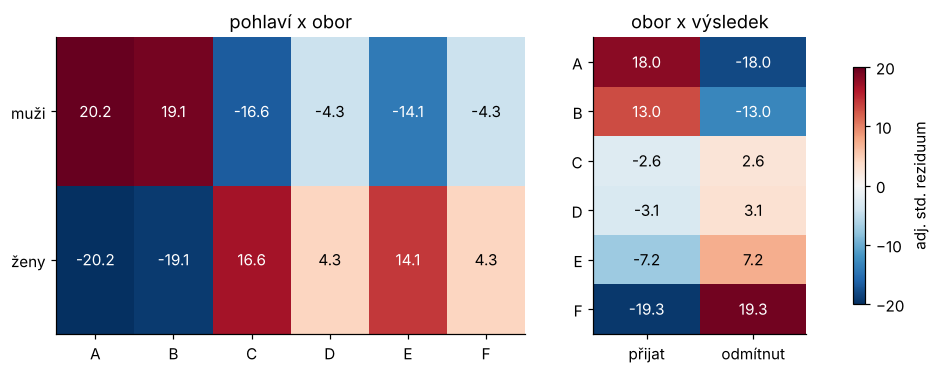

         A     B     C    D     E    F
muži  20.2  19.1 -16.6 -4.3 -14.1 -4.3
ženy -20.2 -19.1  16.6  4.3  14.1  4.3


In [9]:
R2 = adj_resid(gender_dept)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [2.2, 1]})
for ax, Rm, xl, yl, tt in [(axs[0], R2, depts, ["muži", "ženy"], "pohlaví x obor"),
                           (axs[1], R, ["přijat", "odmítnut"], depts, "obor x výsledek")]:
    im = ax.imshow(Rm, cmap="RdBu_r", vmin=-20, vmax=20, aspect="auto")
    ax.set_xticks(range(len(xl)), xl); ax.set_yticks(range(len(yl)), yl); ax.grid(False)
    for (i, j), v in np.ndenumerate(Rm):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if abs(v) > 12 else "black")
    ax.set_title(tt)
fig.colorbar(im, ax=axs, shrink=0.8, label="adj. std. reziduum")
plt.show()
print(pd.DataFrame(R2, index=["muži", "ženy"], columns=depts).round(1))

Levý panel: muži se hlásili výrazně častěji na obory A a B (rezidua $+20{,}2$ a $+19{,}1$), ženy na obory C a E (rezidua $+16{,}6$ a $+14{,}1$)
a mírněji D, F ($+4{,}3$). Ženy se tedy hlásily převážně na obory s nízkou úspěšností přijetí.

### Mozaikový graf

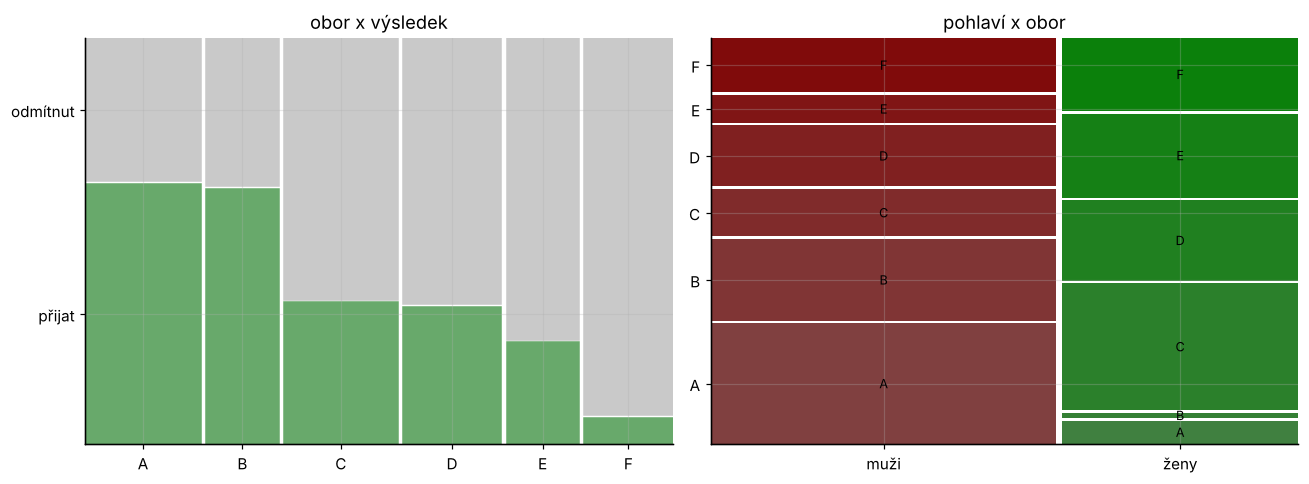

In [10]:
data = {(d, a): dept_adm[k, j] for k, d in enumerate(depts) for j, a in enumerate(["přijat", "odmítnut"])}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
mosaic(data, ax=axs[0], gap=0.01, title="obor x výsledek",
       properties=lambda key: {"color": "#68a96b" if key[1] == "přijat" else "#c9c9c9"},
       labelizer=lambda key: "")
data2 = {(g, d): gender_dept[i, k] for i, g in enumerate(["muži", "ženy"]) for k, d in enumerate(depts)}
mosaic(data2, ax=axs[1], gap=0.01, title="pohlaví x obor", labelizer=lambda key: key[1])
plt.tight_layout(); plt.show()

Vlevo: šířka sloupce odpovídá počtu uchazečů v oboru, zelená výška podílu přijatých – ta s oborem silně klesá (A přes 60 %, F pod 10 %).
Vpravo: rozložení oborů se u mužů a žen zřetelně liší (u žen téměř chybí obory A, B).

---
# 4. Čtyřpolní tabulky

## 4.1 Poměr šancí a interval spolehlivosti
$$b=\frac{n_{11}n_{22}}{n_{12}n_{21}},\qquad SE(\ln b)=\sqrt{\tfrac1{n_{11}}+\tfrac1{n_{12}}+\tfrac1{n_{21}}+\tfrac1{n_{22}}},\qquad
\text{IS: }\exp\big(\ln b\pm z_{1-\alpha/2}SE\big).$$

In [11]:
b = n11 * n22 / (n12 * n21)
se = np.sqrt((1 / table).sum())
D = np.log(b) / se
z = norm.ppf(0.975)
ci = np.exp(np.log(b) + np.array([-1, 1]) * z * se)
print(f"b = {b:.3f}, SE(ln b) = {se:.4f}, D = {D:.3f}, p = {2 * norm.sf(abs(D)):.3g}")
print("95% IS pro beta:", ci.round(3))
t22 = Table2x2(table)
print("statsmodels:", t22.oddsratio, np.round(t22.oddsratio_confint(), 3), t22.log_oddsratio_pvalue())
print("relativní riziko:", t22.riskratio, np.round(t22.riskratio_confint(), 3))

b = 6.000, SE(ln b) = 0.4564, D = 3.926, p = 8.65e-05
95% IS pro beta: [ 2.453 14.678]
statsmodels: 6.0 [ 2.453 14.678] 8.653239824768909e-05
relativní riziko: 2.25 [1.508 3.357]


$b=6$, 95% IS $(2{,}45;\ 14{,}68)$ – interval je silně nesymetrický kolem $b$ (symetrický je až na logaritmické škále).
Waldův test $D=3{,}93$, $p=8{,}7\cdot10^{-5}$. Pro srovnání je uvedeno i relativní riziko $p_{1|1}/p_{1|2}=0{,}75/0{,}33=2{,}25$,
které na rozdíl od OR závisí na schématu výběru.

### Pokrytí Waldova intervalu pro OR – simulace

In [12]:
def coverage(n_per_group, p1, p2, B=5000, rng=RNG):
    beta = (p1 / (1 - p1)) / (p2 / (1 - p2))
    hit = valid = 0
    for _ in range(B):
        x1, x2 = rng.binomial(n_per_group, p1), rng.binomial(n_per_group, p2)
        t = np.array([[x1, n_per_group - x1], [x2, n_per_group - x2]], float) + 0.5   # Haldane-Anscombe
        lb = np.log(t[0, 0] * t[1, 1] / (t[0, 1] * t[1, 0])); s = np.sqrt((1 / t).sum())
        hit += (lb - z * s < np.log(beta) < lb + z * s); valid += 1
    return hit / valid

for ng in [10, 20, 50, 200]:
    print(f"n = {ng:3d} v každé skupině: pokrytí 95% IS = {coverage(ng, 0.3, 0.1):.3f}")

n =  10 v každé skupině: pokrytí 95% IS = 0.979
n =  20 v každé skupině: pokrytí 95% IS = 0.976
n =  50 v každé skupině: pokrytí 95% IS = 0.964
n = 200 v každé skupině: pokrytí 95% IS = 0.948


I při malých skupinách (s korekcí $+0{,}5$) má Waldův interval pro $\ln\beta$ pokrytí blízké nominálním 95 %, spíše vyšší
(je mírně konzervativní); s rostoucím $n$ se pokrytí blíží 0,95.

## 4.2 Fisherův exaktní test

In [13]:
observed = np.array([[8, 2], [1, 5]])
r1, r2 = observed.sum(1); c1 = observed[:, 0].sum(); N = observed.sum()
prob = lambda a: comb(r1, a) * comb(r2, c1 - a) / comb(N, c1)
p_obs = prob(observed[0, 0])
rows_ = []
for a in range(max(0, c1 - r2), min(r1, c1) + 1):
    rows_.append({"n11": a, "tabulka": [[a, r1 - a], [c1 - a, r2 - c1 + a]], "P": prob(a),
                  "započítat": prob(a) <= p_obs * (1 + 1e-7)})
dfF = pd.DataFrame(rows_)
print(dfF.round(4).to_string(index=False))
print("p-hodnota ručně:", dfF.loc[dfF["započítat"], "P"].sum())
res = fisher_exact(observed)
print("scipy fisher_exact:", res.statistic, res.pvalue)
print("očekávané četnosti:\n", expected_freq(observed))
print("chi2 bez korekce p =", chi2_contingency(observed, correction=False).pvalue,
      ", s Yatesovou korekcí p =", chi2_contingency(observed).pvalue)
print("Barnard p =", stats.barnard_exact(observed).pvalue, ", Boschloo p =", stats.boschloo_exact(observed).pvalue)

 n11          tabulka      P  započítat
   3 [[3, 7], [6, 0]] 0.0105       True
   4 [[4, 6], [5, 1]] 0.1101      False
   5 [[5, 5], [4, 2]] 0.3304      False
   6 [[6, 4], [3, 3]] 0.3671      False
   7 [[7, 3], [2, 4]] 0.1573      False
   8 [[8, 2], [1, 5]] 0.0236       True
   9 [[9, 1], [0, 6]] 0.0009       True
p-hodnota ručně: 0.03496503496503496
scipy fisher_exact: 20.0 0.034965034965034975
očekávané četnosti:
 [[5.625 4.375]
 [3.375 2.625]]
chi2 bez korekce p = 0.013425424881491248 , s Yatesovou korekcí p = 0.050961936967763424


Barnard p = 0.021270751953124997 , Boschloo p = 0.024384872263939393


Pozorovaná tabulka ($n_{11}=8$) má pravděpodobnost $0{,}0236$; méně nebo stejně pravděpodobné jsou tabulky s $n_{11}=3$ a $9$,
takže $p=0{,}0105+0{,}0236+0{,}0009=0{,}0350$ – shoda se `scipy`. Očekávané četnosti jsou pod 5, $\chi^2$ test není vhodný:
bez korekce dává menší p-hodnotu ($0{,}013$), s Yatesovou korekcí naopak větší ($0{,}051$, tj. těsně nad hranicí 5 %) – Fisherova p-hodnota $0{,}035$ leží mezi nimi.
Nepodmíněné testy Barnardův ($p=0{,}021$) a Boschlooův ($p=0{,}024$) dávají menší p-hodnotu než Fisherův (bývají silnější).

## 4.3 Skutečná hladina testů v tabulce $2\times2$ – simulace
Dvě skupiny po 15 pozorováních se stejnou pravděpodobností úspěchu $\pi$ (platí $H_0$). Jak často testy na hladině 5 % zamítají?

In [14]:
def size_sim(n_g, pi, B=4000, rng=RNG):
    rej = np.zeros(3); cnt = 0
    for _ in range(B):
        x1, x2 = rng.binomial(n_g, pi, size=2)
        t = np.array([[x1, n_g - x1], [x2, n_g - x2]])
        if (t.sum(0) == 0).any():
            continue
        cnt += 1
        rej[0] += chi2_contingency(t, correction=False).pvalue < 0.05
        rej[1] += chi2_contingency(t, correction=True).pvalue < 0.05
        rej[2] += fisher_exact(t).pvalue < 0.05
    return rej / cnt

out = pd.DataFrame({pi: size_sim(15, pi) for pi in [0.1, 0.3, 0.5]},
                   index=["Pearson bez korekce", "Pearson + Yates", "Fisher"]).T
out.index.name = "pi"
print(out.round(4))

     Pearson bez korekce  Pearson + Yates  Fisher
pi                                               
0.1               0.0251           0.0008  0.0037
0.3               0.0562           0.0150  0.0173
0.5               0.0422           0.0127  0.0127


Fisherův test i Yatesova korekce jsou výrazně **konzervativní** (skutečná hladina 0,1–1,7 %, tj. hluboko pod 5 %). Pearsonův test bez korekce
se nominální hladině blíží nejvíce (4,2 % a 5,6 % pro $\pi=0{,}5$ a $0{,}3$); při $\pi=0{,}1$ (očekávané četnosti kolem 1,5) je jeho skutečná hladina jen 2,5 %
a chování obecně nestabilní – může být i mírně liberální.
Konzervativnost Fisherova testu je cenou za exaktní kontrolu chyby I. druhu u diskrétní statistiky.

### Fisherův test pro tabulku $r\times c$ (Monte Carlo)

In [15]:
t23 = np.array([[8, 2, 1], [1, 5, 3]])
res_mc = fisher_exact(t23, method=stats.MonteCarloMethod(n_resamples=20000, rng=np.random.default_rng(1)))
print("Fisher-Freeman-Halton (MC): p =", res_mc.pvalue)
print("chi2: p =", chi2_contingency(t23).pvalue, "; min. očekávaná četnost =", expected_freq(t23).min().round(2))

Fisher-Freeman-Halton (MC): p = 0.020748962551872405
chi2: p = 0.0223012963531567 ; min. očekávaná četnost = 1.8


U tabulky $2\times3$ s malými četnostmi dává Monte Carlo verze exaktního testu $p\approx0{,}021$; asymptotický $\chi^2$ test zde
vyšel podobně ($p=0{,}022$), ale při tak malých očekávaných četnostech (min. $1{,}8$) se na aproximaci obecně spoléhat nelze.

---
# 5. Párová data: McNemar, Bowker, Stuart–Maxwell

## 5.1 McNemarův test – oba příklady z přednášky

In [16]:
for (a11, a12, a21, a22) in [(30, 10, 20, 40), (20, 0, 5, 25)]:
    s = (a12 - a21) ** 2 / (a12 + a21)
    s_cc = (abs(a12 - a21) - 1) ** 2 / (a12 + a21)
    pe = binomtest(a12, a12 + a21, 0.5).pvalue
    tab = [[a11, a12], [a21, a22]]
    print(f"n12={a12:2d}, n21={a21:2d}: chi2 = {s:.3f} (p = {chi2.sf(s, 1):.4f}), "
          f"s korekcí {s_cc:.2f} (p = {chi2.sf(s_cc, 1):.4f}), exaktní p = {pe:.4f}")
    print("   statsmodels:", mcnemar(tab, exact=False, correction=False).pvalue, mcnemar(tab, exact=True).pvalue)

n12=10, n21=20: chi2 = 3.333 (p = 0.0679), s korekcí 2.70 (p = 0.1003), exaktní p = 0.0987
   statsmodels: 0.06788915486182893 0.09873714670538905
n12= 0, n21= 5: chi2 = 5.000 (p = 0.0253), s korekcí 3.20 (p = 0.0736), exaktní p = 0.0625
   statsmodels: 0.025347318677468325 0.0625


První příklad: $\chi^2=3{,}33$, $p=0{,}068$, exaktní binomický test $p=0{,}099$ – obě varianty $H_0$ nezamítají.
(Ve starší verzi slidů byla exaktní p-hodnota chybně uvedena jako $0{,}377$; správně je $2\,\P(Bi(30;0{,}5)\le10)=0{,}0987$.)

Druhý příklad: asymptotický test $p=0{,}0253$ zamítá, exaktní $p=0{,}0625$ nezamítá; s korekcí na spojitost $p=0{,}074$.
Při pěti nesouhlasných párech je správné použít exaktní test.

### Proč $\chi^2$ test zahrnuje jen nesouhlasné páry – podmíněné rozdělení
Za $H_0$ a při daném $n_d=n_{12}+n_{21}$ je $n_{12}\sim Bi(n_d,1/2)$. Ověříme simulací.

In [17]:
p_disc = 0.15                          # P(nesouhlasný pár) = p12 + p21, p12 = p21
sims = RNG.multinomial(100, [0.35, p_disc / 2, p_disc / 2, 0.5], size=20000)
sel = sims[:, 1] + sims[:, 2] == 15
emp = np.bincount(sims[sel, 1], minlength=16) / sel.sum()
print("počet simulací s n_d = 15:", sel.sum())
print("max |empirické - Bi(15, 1/2)| =", np.abs(emp - stats.binom.pmf(np.arange(16), 15, 0.5)).max().round(4))

počet simulací s n_d = 15: 2200
max |empirické - Bi(15, 1/2)| = 0.0111


Empirické rozdělení $n_{12}$ při $n_d=15$ se od $Bi(15;1/2)$ liší jen o simulační chybu (řádově $10^{-2}$).

## 5.2 Bowkerův test symetrie a Stuartův–Maxwellův test marginální homogenity
$$X^2_B=\sum_{i<j}\frac{(n_{ij}-n_{ji})^2}{n_{ij}+n_{ji}}\sim\chi^2\!\Big(\tfrac{c(c-1)}2\Big),\qquad
Q={\bm d^*}^T\bm V^{-1}\bm d^*\sim\chi^2(c-1),$$
$V_{ii}=n_{i\bullet}+n_{\bullet i}-2n_{ii}$, $V_{ij}=-(n_{ij}+n_{ji})$.

In [18]:
def bowker(T):
    T = np.asarray(T, float); c = T.shape[0]; s = 0.0
    for i in range(c):
        for j in range(i + 1, c):
            if T[i, j] + T[j, i] > 0:
                s += (T[i, j] - T[j, i]) ** 2 / (T[i, j] + T[j, i])
    df = c * (c - 1) // 2
    return s, df, chi2.sf(s, df)

def stuart_maxwell(T, drop=-1):
    T = np.asarray(T, float); c = T.shape[0]
    rows, cols = T.sum(1), T.sum(0)
    V = -(T + T.T)
    np.fill_diagonal(V, rows + cols - 2 * np.diag(T))
    keep = np.delete(np.arange(c), drop)
    d = (rows - cols)[keep]
    Q = d @ np.linalg.solve(V[np.ix_(keep, keep)], d)
    return Q, c - 1, chi2.sf(Q, c - 1)

T = np.array([[40, 8, 2], [10, 35, 5], [3, 7, 40]])
st = SquareTable(T, shift_zeros=False)
print("Bowker ručně:", np.round(bowker(T), 4), "| statsmodels:", st.symmetry().statistic, st.symmetry().pvalue)
for drop in range(3):
    print(f"Stuart-Maxwell (vynechán rozdíl {drop + 1}):", np.round(stuart_maxwell(T, drop), 4))
print("statsmodels homogeneity:", st.homogeneity().statistic, st.homogeneity().pvalue)

Bowker ručně: [0.7556 3.     0.8601] | statsmodels: 0.7555555555555555 0.8600652842442031
Stuart-Maxwell (vynechán rozdíl 1): [0.7377 2.     0.6915]
Stuart-Maxwell (vynechán rozdíl 2): [0.7377 2.     0.6915]
Stuart-Maxwell (vynechán rozdíl 3): [0.7377 2.     0.6915]
statsmodels homogeneity: 0.7377049180327905 0.6915274315614182


Ruční výpočty souhlasí se `statsmodels` ($X^2_B=0{,}756$, $p=0{,}86$; $Q=0{,}738$, $p=0{,}69$) a $Q$ skutečně nezávisí na tom,
který rozdíl marginálů vynecháme.

**Poznámka k chybě ve starších materiálech:** \uv{zjednodušená varianta} se skalárními rozptyly $v_i=n-(n_{i\bullet}+n_{\bullet i})$
a součtem $\sum d_i^2/v_i$ není správný odhad rozptylu $d_i$ (ten je $n_{i\bullet}+n_{\bullet i}-2n_{ii}$) a ignoruje kovariance,
proto byla vypuštěna. Ukážeme, jak moc se liší:

In [19]:
rows, cols = T.sum(1), T.sum(0); nT = T.sum()
d = rows - cols
wrong = np.sum(d ** 2 / (nT - (rows + cols)))
diag_only = np.sum(d ** 2 / (rows + cols - 2 * np.diag(T)))
print(f"chybná 'zjednodušená' statistika: {wrong:.4f}")
print(f"jen diagonála správné V (bez kovariancí): {diag_only:.4f}")
print(f"správná Stuart-Maxwell Q: {stuart_maxwell(T)[0]:.4f}")

chybná 'zjednodušená' statistika: 0.3613
jen diagonála správné V (bez kovariancí): 0.9207
správná Stuart-Maxwell Q: 0.7377


Chybná varianta dává zcela jinou hodnotu než správná statistika $Q$ – i když zde shodou okolností vede ke stejnému (nezamítavému) závěru.

### Symetrie vs. marginální homogenita – cyklický příklad
Tabulka, ve které se přechody $1\to2\to3\to1$ vzájemně vyruší: marginály jsou totožné, ale tabulka není symetrická.

In [20]:
Tc = np.array([[30, 20, 5], [5, 30, 20], [20, 5, 30]])
print("řádkové součty:", Tc.sum(1), " sloupcové součty:", Tc.sum(0))
print("Bowker:", np.round(bowker(Tc), 5))
stc = SquareTable(Tc, shift_zeros=False)
print("Stuart-Maxwell (statsmodels):", stc.homogeneity().statistic, stc.homogeneity().pvalue)

řádkové součty: [55 55 55]  sloupcové součty: [55 55 55]
Bowker: [27.  3.  0.]
Stuart-Maxwell (statsmodels): 0.0 1.0


Marginály jsou shodné ($Q=0$, $p=1$), Bowkerův test ale symetrii jednoznačně zamítá ($X^2_B=27$, df $=3$, $p\approx6\cdot10^{-6}$).
Symetrie implikuje marginální homogenitu, ale ne naopak.

---
# 6. Trojrozměrná tabulka UCBAdmissions

$A$ = výsledek (přijat/odmítnut), $B$ = pohlaví, $C$ = obor A–F, $n=4526$ (Bickel, Hammel, O'Connell 1975).

In [21]:
rate = tabs[:, :, 0] / tabs.sum(axis=2)
marg = tabs.sum(axis=0)
summary = pd.DataFrame({"muži n": tabs[:, 0].sum(1), "ženy n": tabs[:, 1].sum(1),
                        "podíl přijatých M": rate[:, 0], "podíl přijatých Ž": rate[:, 1],
                        "OR (M/Ž)": [Table2x2(t).oddsratio for t in tabs],
                        "p (chi2)": [chi2_contingency(t, correction=False).pvalue for t in tabs]}, index=depts)
print(summary.round(3))
print("\ncelkem: podíl přijatých M =", round(marg[0, 0] / marg[0].sum(), 3), ", Ž =", round(marg[1, 0] / marg[1].sum(), 3))
t_marg = Table2x2(marg)
print("marginální OR =", round(t_marg.oddsratio, 3), "IS", np.round(t_marg.oddsratio_confint(), 3),
      ", chi2 p =", chi2_contingency(marg, correction=False).pvalue)

   muži n  ženy n  podíl přijatých M  podíl přijatých Ž  OR (M/Ž)  p (chi2)
A     825     108              0.621              0.824     0.349     0.000
B     560      25              0.630              0.680     0.803     0.614
C     325     593              0.369              0.341     1.133     0.385
D     417     375              0.331              0.349     0.921     0.585
E     191     393              0.277              0.239     1.222     0.317
F     373     341              0.059              0.070     0.828     0.535

celkem: podíl přijatých M = 0.445 , Ž = 0.304
marginální OR = 1.841 IS [1.624 2.087] , chi2 p = 7.813600388994724e-22


**Simpsonův paradox:** celkově jsou muži přijímáni častěji (44,5 % vs. 30,4 %, OR $=1{,}84$, vysoce významné),
v jednotlivých oborech však OR kolísají kolem 1 a v oborech A, B, D, F mají vyšší úspěšnost ženy.
Významný rozdíl je jen v oboru A ($p=3\cdot10^{-5}$), a to **ve prospěch žen** (OR $=0{,}35$); v ostatních oborech jsou p-hodnoty 0,32–0,61.

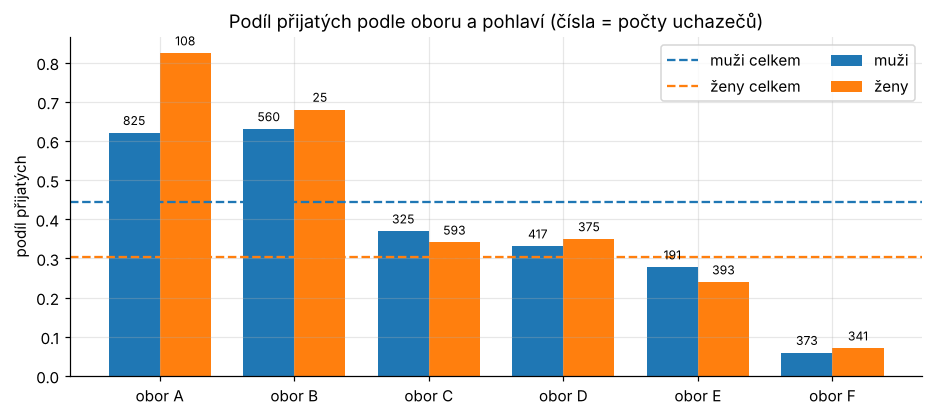

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(6); w = 0.38
sizes = tabs.sum(axis=2)
ax.bar(x - w / 2, rate[:, 0], w, label="muži"); ax.bar(x + w / 2, rate[:, 1], w, label="ženy")
ax.axhline(marg[0, 0] / marg[0].sum(), color="C0", ls="--", label="muži celkem")
ax.axhline(marg[1, 0] / marg[1].sum(), color="C1", ls="--", label="ženy celkem")
for k in range(6):
    ax.text(k - w / 2, rate[k, 0] + 0.02, sizes[k, 0], ha="center", fontsize=8)
    ax.text(k + w / 2, rate[k, 1] + 0.02, sizes[k, 1], ha="center", fontsize=8)
ax.set_xticks(x, [f"obor {d}" for d in depts]); ax.set_ylabel("podíl přijatých"); ax.legend(ncol=2)
ax.set_title("Podíl přijatých podle oboru a pohlaví (čísla = počty uchazečů)")
plt.show()

Graf ukazuje mechanismus paradoxu: ženy se hlásily hlavně na obory C–F s nízkou úspěšností (stovky uchazeček), na obory A, B s vysokou
úspěšností jen málo (108 a 25), zatímco muži převážně na A a B.

## 6.1 Cochranův–Mantelův–Haenszelův test a Breslowův–Dayův test
Výpočet ručně podle vzorců z přednášky a kontrola `StratifiedTable`.

In [23]:
n11k = tabs[:, 0, 0].astype(float)
r1k, r2k = tabs[:, 0].sum(1), tabs[:, 1].sum(1)
c1k, c2k = tabs[:, :, 0].sum(1), tabs[:, :, 1].sum(1)
nk = tabs.sum(axis=(1, 2)).astype(float)
E = r1k * c1k / nk
Var = r1k * r2k * c1k * c2k / (nk ** 2 * (nk - 1))
cmh = (n11k - E).sum() ** 2 / Var.sum()
or_mh = (tabs[:, 0, 0] * tabs[:, 1, 1] / nk).sum() / (tabs[:, 0, 1] * tabs[:, 1, 0] / nk).sum()
print(f"ručně: CMH = {cmh:.4f}, p = {chi2.sf(cmh, 1):.4f}, OR_MH = {or_mh:.4f}")

stt = StratifiedTable(tabs.transpose(1, 2, 0))
print("statsmodels: OR_MH =", stt.oddsratio_pooled, "IS", np.round(stt.oddsratio_pooled_confint(), 4))
print("CMH:", stt.test_null_odds(correction=False).statistic, stt.test_null_odds(correction=False).pvalue)
bd = stt.test_equal_odds()
print("Breslow-Day:", bd.statistic, bd.pvalue)
bd_noA = StratifiedTable(tabs[1:].transpose(1, 2, 0)).test_equal_odds()
print("Breslow-Day bez oboru A:", bd_noA.statistic, bd_noA.pvalue)
print("CMH bez oboru A: p =", StratifiedTable(tabs[1:].transpose(1, 2, 0)).test_null_odds().pvalue)

ručně: CMH = 1.5246, p = 0.2169, OR_MH = 0.9047
statsmodels: OR_MH = 0.9046968282586231 IS [0.7719 1.0603]
CMH: 1.5246066604434356 0.21692369705551817
Breslow-Day: 18.825513705236514 0.0020713903499175457
Breslow-Day bez oboru A: 2.558209212380304 0.6342437359003376
CMH bez oboru A: p = 0.7236905148474911


- Společný MH odhad $\hat\beta_{MH}=0{,}905$ (95% IS $0{,}772$–$1{,}060$): po zohlednění oboru nemají muži žádnou výhodu.
- CMH: $\chi^2_{MH}=1{,}52$, $p=0{,}217$ – podmíněnou nezávislost pohlaví a výsledku při daném oboru nezamítáme.
- Breslow–Day: $18{,}83$, df $=5$, $p=0{,}002$ – poměry šancí nejsou homogenní. Bez oboru A je $p=0{,}63$, heterogenitu tedy způsobuje
  jen obor A (kde jsou ve výhodě ženy). Bez oboru A ani CMH nezamítá podmíněnou nezávislost ($p=0{,}72$).

---
# 7. Log-lineární modely

## 7.1 Uzavřené odhady M1–M3 a jejich kontrola
Pole `n[i, j, k]`: $i$ = výsledek $A$, $j$ = pohlaví $B$, $k$ = obor $C$ ($I=J=2$, $K=6$).

In [24]:
n3 = tabs.transpose(2, 1, 0).astype(float)          # A x B x C
I, J, K = n3.shape
N = n3.sum()
nA, nB, nC = n3.sum((1, 2)), n3.sum((0, 2)), n3.sum((0, 1))
nAB, nAC, nBC = n3.sum(2), n3.sum(1), n3.sum(0)

closed = {
    "[A][B][C]": nA[:, None, None] * nB[None, :, None] * nC[None, None, :] / N ** 2,
    "[AB][C]":   nAB[:, :, None] * nC[None, None, :] / N,
    "[AC][B]":   nAC[:, None, :] * nB[None, :, None] / N,
    "[BC][A]":   nA[:, None, None] * nBC[None, :, :] / N,
    "[AC][BC]":  nAC[:, None, :] * nBC[None, :, :] / nC[None, None, :],
    "[AB][BC]":  nAB[:, :, None] * nBC[None, :, :] / nB[None, :, None],
    "[AB][AC]":  nAB[:, :, None] * nAC[:, None, :] / nA[:, None, None],
}
dfs = {"[A][B][C]": I*J*K - I - J - K + 2, "[AB][C]": (I*J - 1)*(K - 1), "[AC][B]": (I*K - 1)*(J - 1),
       "[BC][A]": (J*K - 1)*(I - 1), "[AC][BC]": K*(I - 1)*(J - 1), "[AB][BC]": J*(I - 1)*(K - 1),
       "[AB][AC]": I*(J - 1)*(K - 1)}

def G2X2(nobs, m):
    return 2 * np.sum(nobs * np.log(nobs / m)), np.sum((nobs - m) ** 2 / m)

rows_ = []
for name, m in closed.items():
    g2, x2 = G2X2(n3, m)
    rows_.append({"model": name, "G2": g2, "X2": x2, "df": dfs[name], "p": chi2.sf(g2, dfs[name])})
res_closed = pd.DataFrame(rows_).set_index("model")
print(res_closed.to_string(formatters={"G2": "{:.2f}".format, "X2": "{:.2f}".format, "p": "{:.3g}".format}))

               G2      X2  df         p
model                                  
[A][B][C] 2097.67 2000.33  16         0
[AB][C]   2004.22 1748.16  15         0
[AC][B]   1242.35 1078.07  11  1.2e-259
[BC][A]    877.06  797.70  11  5.3e-181
[AC][BC]    21.74   19.94   6   0.00135
[AB][BC]   783.61  715.30  10 6.89e-162
[AB][AC]  1148.90 1015.71  10 1.51e-240


Hodnoty $G^2$, $X^2$ a df souhlasí s tabulkou ve slidech (např. $[AC][BC]$: $G^2=21{,}74$, $X^2=19{,}94$, df $=6$).
Velmi malé p-hodnoty modelů M1 a $[AB][C]$ se v dvojnásobné přesnosti zaokrouhlí na 0 (skutečně jsou pod $10^{-300}$).

## 7.2 IPF pro libovolný hierarchický model
Obecná funkce: cyklicky přizpůsobujeme odhad marginálům generujících tříd.

In [25]:
def ipf(nobs, generators, tol=1e-10, max_iter=1000):
    m = np.ones_like(nobs, dtype=float)
    axes_all = set(range(nobs.ndim))
    for it in range(1, max_iter + 1):
        m_old = m.copy()
        for gen in generators:                     # gen = osy, které třída obsahuje, např. (0, 1) = AB
            other = tuple(sorted(axes_all - set(gen)))
            m *= nobs.sum(axis=other, keepdims=True) / m.sum(axis=other, keepdims=True)
        if np.abs(m - m_old).max() < tol:
            return m, it
    return m, it

gens = {"[AC][BC]": [(0, 2), (1, 2)], "[AB][AC]": [(0, 1), (0, 2)],
        "[AB][AC][BC]": [(0, 1), (0, 2), (1, 2)]}
for name, g in gens.items():
    m, it = ipf(n3, g)
    g2, x2 = G2X2(n3, m)
    extra = f", max |IPF - uzavřený tvar| = {np.abs(m - closed[name]).max():.1e}" if name in closed else ""
    print(f"{name:14s} iterací: {it:3d}, G2 = {g2:.2f}, X2 = {x2:.2f}{extra}")
m4_ipf, _ = ipf(n3, gens["[AB][AC][BC]"])

[AC][BC]       iterací:   2, G2 = 21.74, X2 = 19.94, max |IPF - uzavřený tvar| = 5.7e-14
[AB][AC]       iterací:   2, G2 = 1148.90, X2 = 1015.71, max |IPF - uzavřený tvar| = 5.7e-14
[AB][AC][BC]   iterací:  28, G2 = 20.20, X2 = 18.82


Pro rozložitelné modely M3 IPF dosáhne přesného (uzavřeného) řešení už v prvním cyklu – iterace 2 jen ověří, že se nic nezměnilo.
Model M4 uzavřený tvar nemá; IPF konverguje za 28 cyklů k $G^2=20{,}20$.

## 7.3 Newton–Raphson ručně
$\bm\lambda^{(t+1)}=\bm\lambda^{(t)}+(\bm X^T\mathrm{diag}(\bm m)\bm X)^{-1}\bm X^T(\bm n-\bm m)$, kde $\bm X$ je návrhová matice modelu M4.

In [26]:
cells = pd.DataFrame(np.indices(n3.shape).reshape(3, -1).T, columns=["a", "b", "c"])
cells["n"] = n3.ravel()
import patsy
Xd = np.asarray(patsy.dmatrix("C(a)*C(b) + C(a)*C(c) + C(b)*C(c)", cells))
nv = cells["n"].values
lam = np.zeros(Xd.shape[1]); lam[0] = np.log(nv.mean())     # start: konstantní m
for t in range(50):
    mv = np.exp(Xd @ lam)
    g = Xd.T @ (nv - mv)
    H = Xd.T @ (Xd * mv[:, None])
    step = np.linalg.solve(H, g)
    lam += step
    loglik = np.sum(nv * np.log(np.exp(Xd @ lam)) - np.exp(Xd @ lam))
    print(f"iterace {t + 1}: |krok| = {np.abs(step).max():.2e}, log-věrohodnost (bez konst.) = {loglik:.4f}")
    if np.abs(step).max() < 1e-10:
        break
m_nr = np.exp(Xd @ lam).reshape(n3.shape)
print("počet parametrů:", Xd.shape[1], ", df =", Xd.size // Xd.shape[1] - Xd.shape[1])
print("max |NR - IPF| =", np.abs(m_nr - m4_ipf).max())

iterace 1: |krok| = 2.61e+00, log-věrohodnost (bez konst.) = 20143.0820
iterace 2: |krok| = 6.35e-01, log-věrohodnost (bez konst.) = 20468.9194
iterace 3: |krok| = 5.79e-01, log-věrohodnost (bez konst.) = 20501.0043
iterace 4: |krok| = 2.91e-01, log-věrohodnost (bez konst.) = 20503.0658
iterace 5: |krok| = 5.22e-02, log-věrohodnost (bez konst.) = 20503.1034
iterace 6: |krok| = 1.41e-03, log-věrohodnost (bez konst.) = 20503.1035
iterace 7: |krok| = 9.95e-07, log-věrohodnost (bez konst.) = 20503.1035
iterace 8: |krok| = 4.95e-13, log-věrohodnost (bez konst.) = 20503.1035
počet parametrů: 19 , df = 5
max |NR - IPF| = 5.411493475548923e-11


Newton–Raphson konverguje kvadraticky – stačí několik iterací (velikost kroku klesá řádově na druhou), oproti 28 cyklům IPF.
Model M4 má 19 parametrů pro 24 buněk, tedy df $=5$. Odhady $\hat m_{ijk}$ obou algoritmů jsou totožné (rozdíl řádu $10^{-10}$ a menší).

## 7.4 Poissonův GLM – všechny modely, parametry a SE

In [27]:
adm = [512, 353, 120, 138, 53, 22, 89, 17, 202, 131, 94, 24]
rej = [313, 207, 205, 279, 138, 351, 19, 8, 391, 244, 299, 317]
d = pd.DataFrame({"C": list("ABCDEF") * 2, "B": ["M"] * 6 + ["F"] * 6})
dfu = pd.concat([d.assign(A="Y", n=adm), d.assign(A="N", n=rej)], ignore_index=True)
models = {"[A][B][C]": "A+B+C", "[AB][C]": "A*B+C", "[AC][B]": "A*C+B", "[BC][A]": "B*C+A",
          "[AC][BC]": "A*C+B*C", "[AB][BC]": "A*B+B*C", "[AB][AC]": "A*B+A*C",
          "[AB][AC][BC]": "A*B+A*C+B*C"}
fits, rows_ = {}, []
for name, f in models.items():
    r = smf.glm("n ~ " + f, dfu, family=sm.families.Poisson()).fit()
    fits[name] = r
    rows_.append({"model": name, "G2": r.deviance, "X2": r.pearson_chi2, "df": int(r.df_resid),
                  "p": chi2.sf(r.deviance, r.df_resid), "AIC": r.aic})
res_glm = pd.DataFrame(rows_).set_index("model")
print(res_glm.to_string(formatters={"G2": "{:.2f}".format, "X2": "{:.2f}".format,
                                    "p": "{:.3g}".format, "AIC": "{:.1f}".format}))
print("\nshoda G2 s uzavřenými tvary:", np.allclose(res_glm.loc[list(closed), "G2"], res_closed["G2"]))

                  G2      X2  df         p    AIC
model                                            
[A][B][C]    2097.67 2000.33  16         0 2272.7
[AB][C]      2004.22 1748.16  15         0 2181.3
[AC][B]      1242.35 1078.07  11  1.2e-259 1427.4
[BC][A]       877.06  797.70  11  5.3e-181 1062.1
[AC][BC]       21.74   19.94   6   0.00135  216.8
[AB][BC]      783.61  715.30  10 6.89e-162  970.7
[AB][AC]     1148.90 1015.71  10 1.51e-240 1336.0
[AB][AC][BC]   20.20   18.82   5   0.00114  217.3

shoda G2 s uzavřenými tvary: True


GLM reprodukuje uzavřené výsledky. Podle AIC je nejlepší model $[AC][BC]$ (AIC 216,8), těsně následovaný M4 (217,3);
všechny modely bez členů $[AC]$ a $[BC]$ jsou o řády horší.

### Porovnání vnořených modelů a parametr $\lambda^{(AB)}$

In [28]:
r3, r4 = fits["[AC][BC]"], fits["[AB][AC][BC]"]
dG2 = r3.deviance - r4.deviance
print(f"[AC][BC] vs [AB][AC][BC]: dG2 = {dG2:.3f}, df = 1, p = {chi2.sf(dG2, 1):.4f}")
lab = r4.params.filter(like="A[T.Y]:B")
print("lambda_AB =", lab.values, " SE =", r4.bse.filter(like="A[T.Y]:B").values)
print("exp(lambda_AB) = podmíněný OR (přijetí, muži vs. ženy) =", np.exp(lab.values))
print("95% IS:", np.exp(r4.conf_int().loc[lab.index].values))
# pořadí řádků dfu: A (Y, N) x B (M, F) x C (A-F) = stejné jako osy pole n3
print("max |GLM - IPF| pro M4:", np.abs(r4.fittedvalues.values.reshape(2, 2, 6) - m4_ipf).max())

[AC][BC] vs [AB][AC][BC]: dG2 = 1.531, df = 1, p = 0.2159
lambda_AB = [-0.0999]  SE = [0.0808]
exp(lambda_AB) = podmíněný OR (přijetí, muži vs. ženy) = [0.905]
95% IS: [[0.7723 1.0603]]
max |GLM - IPF| pro M4: 6.014033715473488e-11


- $\Delta G^2=1{,}53$ při 1 df ($p=0{,}22$): člen $[AB]$ (přímá vazba pohlaví–výsledek při daném oboru) není potřeba – stejný závěr jako CMH test.
- V M4 je $\exp(\hat\lambda^{(AB)})=0{,}905$ (95% IS $0{,}77$–$1{,}06$) – společný podmíněný OR přijetí mužů vs. žen,
  prakticky totožný s Mantelovým–Haenszelovým odhadem $0{,}905$.
- GLM a IPF dávají stejné $\hat m$ (rozdíl řádu $10^{-10}$).

### Bez oboru A

In [29]:
dfu2 = dfu[dfu.C != "A"]
for name in ["[AC][BC]", "[AB][AC][BC]"]:
    r = smf.glm("n ~ " + models[name], dfu2, family=sm.families.Poisson()).fit()
    print(f"{name:14s} G2 = {r.deviance:.2f}, df = {r.df_resid:.0f}, p = {chi2.sf(r.deviance, r.df_resid):.3f}")

[AC][BC]       G2 = 2.68, df = 5, p = 0.749
[AB][AC][BC]   G2 = 2.56, df = 4, p = 0.635


Po vynechání oboru A model podmíněné nezávislosti $[AC][BC]$ vyhovuje ($G^2=2{,}68$, df $=5$, $p=0{,}75$): v oborech B–F
výsledek přijetí nezávisí na pohlaví, jakmile známe obor.

### Pearsonova rezidua modelu $[AC][BC]$

In [30]:
res3 = pd.DataFrame({"obor": dfu.C, "pohlaví": dfu.B, "výsledek": dfu.A,
                     "n": dfu.n, "m_hat": r3.fittedvalues.round(1), "rezid": r3.resid_pearson.round(2)})
print(res3.pivot_table(index="obor", columns=["pohlaví", "výsledek"], values="rezid"))

pohlaví      F           M      
výsledek     N     Y     N     Y
obor                            
A        -3.13  2.33  1.13 -0.84
B        -0.39  0.30  0.08 -0.06
C         0.31 -0.42 -0.41  0.56
D        -0.23  0.32  0.22 -0.31
E         0.29 -0.49 -0.41  0.71
F        -0.11  0.43  0.11 -0.41


Výraznější rezidua má model jen v oboru A: ženy tam byly přijaty častěji ($e=+2{,}33$) a odmítnuty méně často ($e=-3{,}13$), než by odpovídalo
podmíněné nezávislosti; u mužů v oboru A jsou rezidua menší ($+1{,}13$, $-0{,}84$), protože jich je mnohem víc. V ostatních oborech jsou rezidua malá ($|e|\le0{,}71$).

---
# Shrnutí

| situace | metoda | Python |
|---|---|---|
| nezávislost / homogenita v $r\times c$ | $X^2$, $G^2$ | `chi2_contingency(t, correction=False)` |
| síla asociace | Cramérovo $V$, $\varphi$, $C$ | `scipy.stats.contingency.association` |
| které buňky | adjustovaná rezidua, mozaikový graf | `Table(t).standardized_resids`, `mosaic` |
| $2\times2$, míra účinku | OR, IS přes $\ln b$ | `Table2x2` |
| malé četnosti | Fisherův (Barnardův, Boschlooův) test | `fisher_exact`, `barnard_exact` |
| párová data $2\times2$ | McNemar (exaktní při malém $n_d$) | `mcnemar`, `binomtest` |
| párová data $c\times c$ | Bowker, Stuart–Maxwell | `SquareTable.symmetry()`, `.homogeneity()` |
| $2\times2\times K$ | CMH, MH OR, Breslow–Day | `StratifiedTable` |
| obecné vícerozměrné tabulky | log-lineární modely (Poissonův GLM, IPF) | `smf.glm(..., family=Poisson())` |

## Úlohy
1. Simulací (sekce 2) zjistěte, při jaké nejmenší očekávané četnosti má $X^2$ test v tabulce $3\times3$ skutečnou hladinu mezi 4 a 6 %.
2. Pro data UCB spočtěte Fisherův exaktní test v každém oboru zvlášť a porovnejte s $\chi^2$ testem.
3. Ověřte, že pro tabulku $2\times2$ je McNemarova statistika rovna Stuartově–Maxwellově i Bowkerově statistice.
4. Upravte funkci `ipf` tak, aby vracela i průběh $G^2$ po cyklech, a vykreslete rychlost konvergence pro model M4.
5. Pro model M4 spočtěte z odhadů $\hat m_{ijk}$ podmíněné poměry šancí $A$–$B$ v jednotlivých oborech a ověřte, že jsou shodné.